# ShuffleNetV2 on the Chest CT-Scan Images dataset (lung cancer, 4 classes)

**ShuffleNetV2 x1.0** (Ma et al., ECCV 2018), the torchvision implementation, fine-tuned end to end from ImageNet weights (`PRETRAINED = False` trains from scratch). Grayscale CT slices are repeated to 3 channels and ImageNet-normalised inside the model.

Outputs: train / val / test loss, accuracy, F1, precision, recall curves; confusion matrices; classification report; ROC; parameters and forward/backward FLOPs.

In [1]:
!pip install -q kagglehub seaborn scikit-learn tqdm pillow

## 1. Config

In [2]:
import os, math, time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import classification_report

# ---------------- model ----------------
PRETRAINED   = True      # ImageNet-pretrained weights, fine-tuned end to end. False = train from scratch
IMG_SIZE     = 224
# ---------------- training ----------------
BATCH_SIZE   = 16
EPOCHS       = 25
LR           = 1e-4 if PRETRAINED else 1e-3
WEIGHT_DECAY = 1e-4
OPTIMIZER    = "adamw"     # 'adam' | 'adamw'
SCHEDULER    = "cosine"      # 'cosine' | 'exp' (ExponentialLR, gamma 0.995 per epoch)
EARLY_STOPPING_PATIENCE = 5     # None = no early stopping
MONITOR      = "val_loss"   # metric for early stopping / best-weights selection ('val_loss' or 'val_f1')
RESTORE_BEST = True         # restore the best-MONITOR weights before the final evaluation (False = use the last epoch)
SEED         = 42

# ---------------- switches (all OFF = plain training) ----------------
USE_AUGMENTATION  = False   # small rotation / shift / scale + brightness-contrast (no flips)
USE_CLASS_WEIGHTS = False   # class-weighted cross-entropy

AVG = "macro"             # averaging for precision / recall / F1
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE = device
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

device: cuda | Tesla T4


## 2. Data

[Chest CT-Scan images Dataset (Kaggle, mohamedhanyyy)](https://www.kaggle.com/datasets/mohamedhanyyy/chest-ctscan-images): 2D CT slices in 4 classes (adenocarcinoma, large cell carcinoma, squamous cell carcinoma, normal) with the dataset's own train / valid / test folders (valid and test use short class names, train the long ones; they are matched by the name before the first underscore). Images are converted to 224x224 grayscale.

In [3]:
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
# os.environ["KAGGLE_USERNAME"] = "your_username"   # only if you do not have ~/.kaggle/kaggle.json
# os.environ["KAGGLE_KEY"]      = "your_key"
KAGGLE_PATH = "/kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data"   # layout: Data/{train,valid,test}
if os.path.exists(KAGGLE_PATH):
    DATA_DIR = KAGGLE_PATH
else:                                   # other layout / not on Kaggle: search, or download with kagglehub
    root = "/kaggle/input"
    if not os.path.exists(root):
        import kagglehub
        root = kagglehub.dataset_download("mohamedhanyyy/chest-ctscan-images")
    DATA_DIR = next((dp for dp, dn, _ in os.walk(root, followlinks=True) if {"train", "valid", "test"} <= set(dn)), None)
    if DATA_DIR is None:
        for dp, dn, _ in os.walk(root, followlinks=True):           # show what is really there
            print(dp, dn[:6])
        raise FileNotFoundError("no folder with train/valid/test found under " + root)
print("DATA_DIR:", DATA_DIR)

CLASS_NAMES = ["adenocarcinoma", "large.cell.carcinoma", "normal", "squamous.cell.carcinoma"]; NUM_CLASSES = 4
def class_index(folder):      # folder names differ between splits (train/valid long names, test short names)
    for i, n in enumerate(CLASS_NAMES):
        if folder.lower().startswith(n): return i
    raise ValueError(folder)

def load_split(split):
    base = os.path.join(DATA_DIR, split); xs, ys = [], []
    items = [(os.path.join(base, d, f), class_index(d)) for d in sorted(os.listdir(base)) for f in sorted(os.listdir(os.path.join(base, d)))
             if f.lower().endswith((".png", ".jpg", ".jpeg"))]
    def one(p): return np.asarray(Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)
    with ThreadPoolExecutor(8) as ex: xs = list(tqdm(ex.map(one, [p for p, _ in items]), total=len(items), desc=split))
    return np.stack(xs), np.array([y for _, y in items])

Xtr, Ytr = load_split("train"); Xva, Yva = load_split("valid"); Xte, Yte = load_split("test")
print(Xtr.shape, Xva.shape, Xte.shape)
for n, y in [("train", Ytr), ("val", Yva), ("test", Yte)]:
    print(f"{n:5s}", dict(zip(CLASS_NAMES, np.bincount(y, minlength=4))))

DATA_DIR: /kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data


train:   0%|          | 0/613 [00:00<?, ?it/s]

valid:   0%|          | 0/72 [00:00<?, ?it/s]

test:   0%|          | 0/315 [00:00<?, ?it/s]

(613, 224, 224) (72, 224, 224) (315, 224, 224)
train {'adenocarcinoma': np.int64(195), 'large.cell.carcinoma': np.int64(115), 'normal': np.int64(148), 'squamous.cell.carcinoma': np.int64(155)}
val   {'adenocarcinoma': np.int64(23), 'large.cell.carcinoma': np.int64(21), 'normal': np.int64(13), 'squamous.cell.carcinoma': np.int64(15)}
test  {'adenocarcinoma': np.int64(120), 'large.cell.carcinoma': np.int64(51), 'normal': np.int64(54), 'squamous.cell.carcinoma': np.int64(90)}


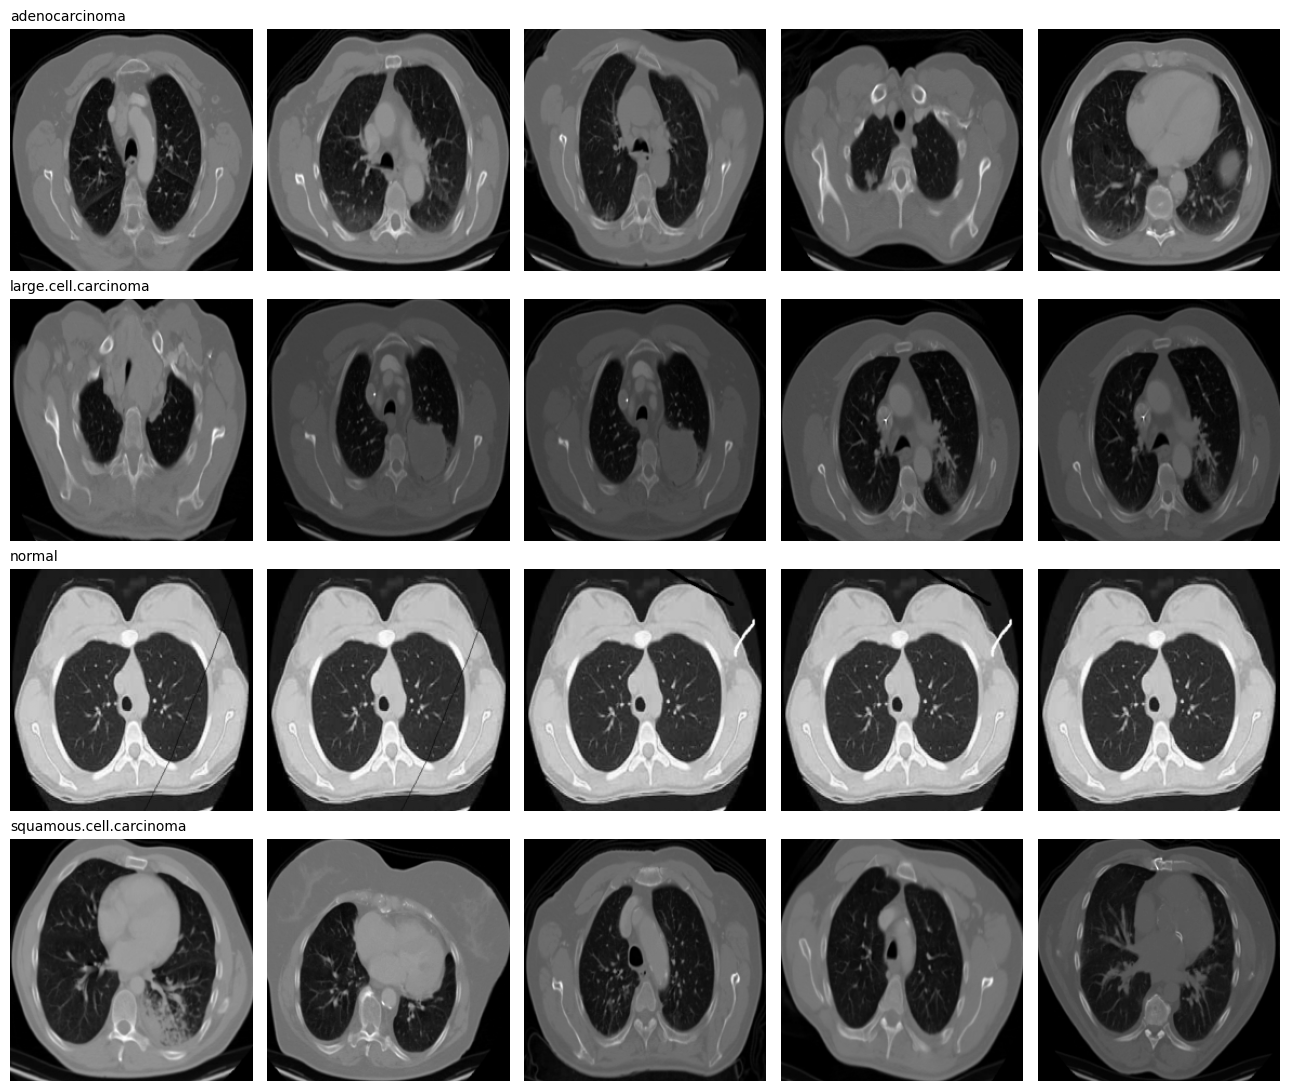

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(4, 5, figsize=(13, 11))
for cls in range(4):
    for a, i in zip(ax[cls], np.where(Ytr == cls)[0][:5]):
        a.imshow(Xtr[i], cmap="gray"); a.axis("off")
    ax[cls][0].set_title(CLASS_NAMES[cls], loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 3. ShuffleNetV2 model

In [5]:
class _Gray3(nn.Module):
    """Input: 1-channel image in [-1, 1] (as served by ArrayLoader). Converted to 3 channels and normalised the way the pretrained weights expect."""
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1)); self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))
    def prep(self, x):
        return ((x * 0.5 + 0.5).repeat(1, 3, 1, 1) - self.mean) / self.std

from torchvision.models import shufflenet_v2_x1_0, ShuffleNet_V2_X1_0_Weights

class Net(_Gray3):
    def __init__(self, num_classes, pretrained=True):
        super().__init__([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        m = None
        if pretrained:
            try:
                m = shufflenet_v2_x1_0(weights=ShuffleNet_V2_X1_0_Weights.IMAGENET1K_V1); print("downloaded ImageNet weights")
            except Exception as e:
                raise RuntimeError("Could not download the ImageNet weights (" + str(e)[:100] + "). Turn Internet on, or set PRETRAINED = False.")
        else:
            m = shufflenet_v2_x1_0(weights=None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        self.m = m
    def forward(self, x):
        return self.m(self.prep(x))

## 4. Training utilities

In [6]:
import math, time, copy, random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, roc_auc_score


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


class ArrayLoader:
    """Serves batches from an in-memory uint8 array (N,H,W). No dataloader workers, no disk reads."""
    def __init__(self, X, Y, bs, shuffle=False, augment=False, drop_last=False):
        self.X = torch.from_numpy(np.ascontiguousarray(X)).unsqueeze(1)
        self.Y = torch.from_numpy(np.asarray(Y)).long()
        self.bs, self.shuffle, self.augment, self.drop_last = bs, shuffle, augment, drop_last

    def __len__(self):
        n = len(self.X)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)

    def _aug(self, x):   # rotation +-10 deg, translation +-5%, scale 0.95-1.05, brightness/contrast. No flips.
        B, d = x.shape[0], x.device
        ang = (torch.rand(B, device=d) * 2 - 1) * math.radians(10)
        s = 1 + (torch.rand(B, device=d) * 2 - 1) * 0.05
        tx, ty = [(torch.rand(B, device=d) * 2 - 1) * 0.1 for _ in range(2)]
        c, si = torch.cos(ang) * s, torch.sin(ang) * s
        theta = torch.stack([torch.stack([c, -si, tx], 1), torch.stack([si, c, ty], 1)], 1)
        x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
        br = torch.rand(B, 1, 1, 1, device=d) * 0.4 - 0.2
        ct = torch.rand(B, 1, 1, 1, device=d) * 0.4 + 0.8
        m = x.mean((1, 2, 3), keepdim=True)
        return ((x - m) * ct + m + br).clamp(0, 1)

    def __iter__(self):
        dev = DEVICE
        idx = torch.randperm(len(self.X)) if self.shuffle else torch.arange(len(self.X))
        for i in range(len(self)):
            b = idx[i * self.bs:(i + 1) * self.bs]
            x = self.X[b].to(dev, non_blocking=True).float().div_(255)
            if self.augment:
                x = self._aug(x)
            yield (x - 0.5) / 0.5, self.Y[b].to(dev, non_blocking=True)


def metrics(y, p, avg):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average=avg, pos_label=1, zero_division=0)
    return dict(acc=accuracy_score(y, p), precision=pr, recall=rc, f1=f1)


def auc_score(y, prob):
    try:
        if prob.shape[1] == 2:
            return roc_auc_score(y, prob[:, 1])
        return roc_auc_score(y, prob, multi_class="ovr", average="macro")
    except ValueError:
        return float("nan")


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    tot, n, ys, ps, pr = 0.0, 0, [], [], []
    for x, y in loader:
        out = model(x).float()
        tot += criterion(out, y).item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(out.argmax(1).cpu()); pr.append(out.softmax(1).cpu())
    return tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(pr).numpy()


def fit(model, train_loader, val_loader, test_loader, criterion, device, avg, epochs=25, lr=1e-4, weight_decay=1e-4,
        optimizer="adamw", scheduler="cosine", gamma=0.995, warmup=0, patience=None, monitor="val_loss", use_amp=True,
        restore_best=True, ckpt="best_model.pt"):
    """optimizer: 'adamw' | 'adam'. scheduler: 'cosine' (optional linear warm-up) | 'exp' (ExponentialLR, gamma per epoch) | 'none'.
    patience: early stopping on `monitor` (e.g. 'val_loss' or 'val_f1'); None = NO early stopping (train all epochs).
    The weights of the best `monitor` epoch are restored at the end. The test set is logged each epoch for the curves only."""
    opt = (torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay) if optimizer == "adam"
           else torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay))
    if scheduler == "cosine":
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: (e + 1) / warmup if e < warmup
                                                  else 0.5 * (1 + math.cos(math.pi * (e - warmup) / max(1, epochs - warmup))))
    elif scheduler == "exp":
        sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=gamma)
    else:
        sched = None
    use_amp = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    keys = ["loss", "acc", "f1", "precision", "recall"]
    hist = {f"{s}_{k}": [] for s in ["train", "val", "test"] for k in keys}
    hist["lr"] = []
    lower_better = monitor.endswith("loss")
    best, best_state, best_ep, bad = (float("inf") if lower_better else -float("inf")), None, 0, 0
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train()
        tot, n, ys, ps = 0.0, 0, [], []
        for x, y in train_loader:
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
            loss = criterion(out.float(), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update()
            tot += loss.item() * x.size(0); n += x.size(0)
            ys.append(y.cpu()); ps.append(out.argmax(1).detach().cpu())
        tr = (tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy())
        vl, vy, vp, _ = evaluate(model, val_loader, criterion)
        sl, sy, sp, _ = evaluate(model, test_loader, criterion)          # monitoring only, never used for selection
        for name, (l, y, p) in [("train", tr), ("val", (vl, vy, vp)), ("test", (sl, sy, sp))]:
            hist[f"{name}_loss"].append(l)
            for k, v in metrics(y, p, avg).items():
                hist[f"{name}_{k}"].append(v)
        hist["lr"].append(opt.param_groups[0]["lr"])
        if sched is not None: sched.step()
        cur = hist[monitor][-1]
        improved = cur < best if lower_better else cur > best
        if improved:
            best, best_ep, bad = cur, ep, 0
            best_state = copy.deepcopy(model.state_dict()); torch.save(best_state, ckpt)
        else:
            bad += 1
        print(f"Ep {ep:02d}/{epochs} | {time.time()-t0:5.1f}s | loss tr {tr[0]:.4f} val {vl:.4f} test {sl:.4f} | "
              f"F1 tr {hist['train_f1'][-1]:.3f} val {hist['val_f1'][-1]:.3f} test {hist['test_f1'][-1]:.3f}"
              + ("  *best*" if improved else (f"  (no improvement {bad}/{patience})" if patience else "")))
        if patience and bad >= patience:
            print(f"Early stopping at epoch {ep}: {monitor} did not improve for {patience} epochs (best epoch {best_ep}).")
            break
    print(f"Best {monitor} = {best:.4f} at epoch {best_ep}" + ("; restoring those weights." if restore_best else "; keeping the LAST-epoch weights (RESTORE_BEST = False)."))
    if restore_best: model.load_state_dict(best_state)
    hist["best_epoch"] = best_ep
    return hist

In [7]:
set_seed(SEED)
cw = None
if USE_CLASS_WEIGHTS:
    cnt = np.bincount(Ytr, minlength=NUM_CLASSES); cw = torch.tensor(cnt.sum() / (NUM_CLASSES * cnt), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=cw)

train_loader = ArrayLoader(Xtr, Ytr, BATCH_SIZE, shuffle=True, augment=USE_AUGMENTATION, drop_last=True)
val_loader   = ArrayLoader(Xva, Yva, BATCH_SIZE * 2)
test_loader  = ArrayLoader(Xte, Yte, BATCH_SIZE * 2)

model = Net(NUM_CLASSES, pretrained=PRETRAINED).to(device)
print("output shape:", model(torch.randn(2, 1, IMG_SIZE, IMG_SIZE, device=device)).shape)

Downloading: "https://download.pytorch.org/models/shufflenetv2_x1-5666bf0f80.pth" to /root/.cache/torch/hub/checkpoints/shufflenetv2_x1-5666bf0f80.pth


100%|██████████| 8.79M/8.79M [00:00<00:00, 93.2MB/s]


downloaded ImageNet weights
output shape: torch.Size([2, 4])


## 5. Parameters and FLOPs (forward / backward, per image and per batch)

In [8]:
import pandas as pd
from torch.utils.flop_counter import FlopCounterMode

def measure_flops(model, batch_size):
    """Forward and backward FLOPs of one training step (1 multiply-add = 2 FLOPs; matmul/conv/attention only)."""
    model.train(); model.zero_grad(set_to_none=True)
    x = torch.randn(batch_size, 1, IMG_SIZE, IMG_SIZE, device=device)
    with FlopCounterMode(display=False) as fc:
        out = model(x); fwd = fc.get_total_flops()
        out.float().sum().backward(); tot = fc.get_total_flops()
    model.zero_grad(set_to_none=True)
    return fwd, tot - fwd

def complexity_report(model):
    total = sum(p.numel() for p in model.parameters()); trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    fb, bb = measure_flops(model, BATCH_SIZE)
    f2, b2 = measure_flops(model, 2)               # per image = batch of 2 / 2 (BatchNorm needs >1 sample in train mode)
    f1, b1 = f2 / 2, b2 / 2
    fmt = lambda v: f"{v/1e6:.2f} M" if v < 1e9 else f"{v/1e9:.3f} G"
    rows = {"Total parameters": total, "Trainable parameters": trainable, "Non-trainable parameters": total - trainable,
            "Forward FLOPs / image": f1, "Backward FLOPs / image": b1, "Forward+Backward FLOPs / image": f1 + b1,
            f"Forward FLOPs / batch ({BATCH_SIZE})": fb, f"Backward FLOPs / batch ({BATCH_SIZE})": bb,
            f"Forward+Backward FLOPs / batch ({BATCH_SIZE})": fb + bb, "Forward MAdds / image (FLOPs/2, paper unit)": f1 / 2}
    df = pd.DataFrame({"value": rows}); df["readable"] = [fmt(v) for v in df["value"]]
    print(f"Input 1 x {IMG_SIZE} x {IMG_SIZE} | batch {BATCH_SIZE}"); display(df); df.to_csv("model_complexity.csv")

complexity_report(model)

Input 1 x 224 x 224 | batch 16


,value,readable
Total parameters,1.257704e+06,1.26 M
Trainable parameters,1.257704e+06,1.26 M
Non-trainable parameters,0.000000e+00,0.00 M
Forward FLOPs / image,2.877762e+08,287.78 M
Backward FLOPs / image,1.413615e+09,1.414 G
Forward+Backward FLOPs / image,1.701391e+09,1.701 G
Forward FLOPs / batch (16),4.604419e+09,4.604 G
Backward FLOPs / batch (16),2.261783e+10,22.618 G
Forward+Backward FLOPs / batch (16),2.722225e+10,27.222 G
"Forward MAdds / image (FLOPs/2, paper unit)",1.438881e+08,143.89 M


## 6. Training

Test metrics are logged each epoch **only** for the curves, never for selection. Early stopping: patience 5 on validation loss; the best-validation-loss weights are restored. The variant is ShuffleNetV2 x1.0 (change `shufflenet_v2_x1_0` for x0.5 / x1.5 / x2.0).

In [9]:
set_seed(SEED)
model = Net(NUM_CLASSES, pretrained=PRETRAINED).to(device)
history = fit(model, train_loader, val_loader, test_loader, criterion, device, AVG,
              epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY, optimizer=OPTIMIZER, scheduler=SCHEDULER,
              patience=EARLY_STOPPING_PATIENCE, monitor=MONITOR, restore_best=RESTORE_BEST, ckpt="best_model.pt")

downloaded ImageNet weights
Ep 01/25 |   4.4s | loss tr 1.3571 val 1.3222 test 1.3117 | F1 tr 0.405 val 0.278 test 0.247  *best*
Ep 02/25 |   1.4s | loss tr 1.2332 val 1.1709 test 1.1538 | F1 tr 0.607 val 0.503 test 0.504  *best*
Ep 03/25 |   1.4s | loss tr 1.1130 val 1.1417 test 1.1021 | F1 tr 0.544 val 0.497 test 0.527  *best*
Ep 04/25 |   1.4s | loss tr 1.0308 val 1.0982 test 1.0433 | F1 tr 0.563 val 0.478 test 0.522  *best*
Ep 05/25 |   1.4s | loss tr 0.9409 val 1.0503 test 0.9537 | F1 tr 0.599 val 0.492 test 0.589  *best*
Ep 06/25 |   1.4s | loss tr 0.8121 val 0.9730 test 0.8238 | F1 tr 0.749 val 0.503 test 0.638  *best*
Ep 07/25 |   1.4s | loss tr 0.6870 val 0.8800 test 0.7461 | F1 tr 0.822 val 0.662 test 0.681  *best*
Ep 08/25 |   1.4s | loss tr 0.5701 val 0.8120 test 0.6609 | F1 tr 0.897 val 0.747 test 0.727  *best*
Ep 09/25 |   1.4s | loss tr 0.4892 val 0.7689 test 0.6180 | F1 tr 0.936 val 0.791 test 0.770  *best*
Ep 10/25 |   1.4s | loss tr 0.3956 val 0.6984 test 0.6052 | F1 

## 7. Curves

In [10]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc as sk_auc
from sklearn.preprocessing import label_binarize

def plot_history(h, avg_name):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(2, 3, figsize=(18, 9)); ax = ax.ravel()
    for a, (k, t) in zip(ax, [("loss", "Loss"), ("acc", "Accuracy"), ("f1", f"F1 ({avg_name})"),
                              ("precision", f"Precision ({avg_name})"), ("recall", f"Recall ({avg_name})")]):
        for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
            a.plot(ep, h[f"{s}_{k}"], label=s, color=c, lw=2)
        a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    ax[5].plot(ep, h["lr"], color="tab:red", lw=2); ax[5].set_title("Learning rate"); ax[5].set_xlabel("epoch"); ax[5].grid(alpha=.3)
    plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

def plot_loss_only(h):
    ep = range(1, len(h["train_loss"]) + 1)
    plt.figure(figsize=(8, 5))
    for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
        plt.plot(ep, h[f"{s}_loss"], label=f"{s} loss", color=c, lw=2)
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Train / Val / Test loss"); plt.grid(alpha=.3); plt.legend()
    plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

def plot_confusion(y, p, names, title, fname):
    n = len(names); cm = confusion_matrix(y, p, labels=range(n)); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    w = max(11, 1.6 * n * 2)
    fig, ax = plt.subplots(1, 2, figsize=(w, max(4.5, 0.9 * n + 2.5)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[0]); ax[0].set_title(f"{title} - counts")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[1], vmin=0, vmax=1)
    ax[1].set_title(f"{title} - normalised by true class")
    for a in ax:
        a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

def plot_roc(y, prob, names, fname="roc_curves.png"):
    plt.figure(figsize=(6.5, 5.5))
    if len(names) == 2:
        fpr, tpr, _ = roc_curve(y, prob[:, 1]); plt.plot(fpr, tpr, lw=2, label=f"{names[1]} (AUC {sk_auc(fpr, tpr):.3f})")
    else:
        yb = label_binarize(y, classes=range(len(names)))
        for i, n in enumerate(names):
            fpr, tpr, _ = roc_curve(yb[:, i], prob[:, i]); plt.plot(fpr, tpr, lw=2, label=f"{n} (AUC {sk_auc(fpr, tpr):.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=.5); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.title("ROC (test)"); plt.legend(loc="lower right", fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(fname, dpi=150); plt.show()

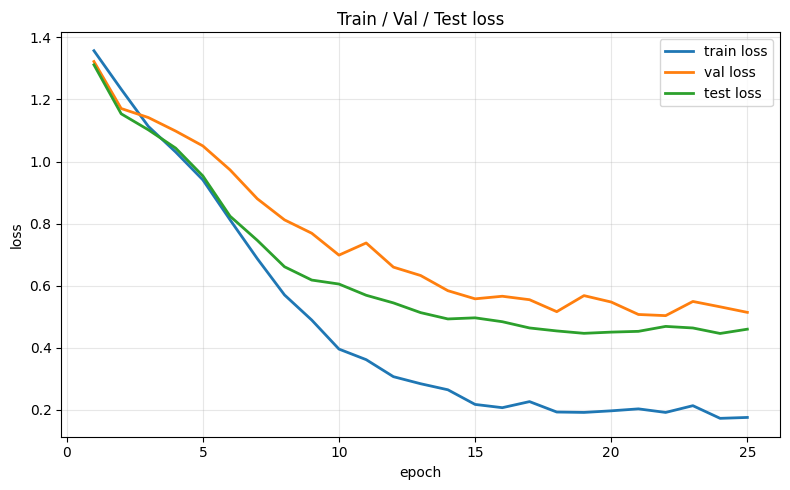

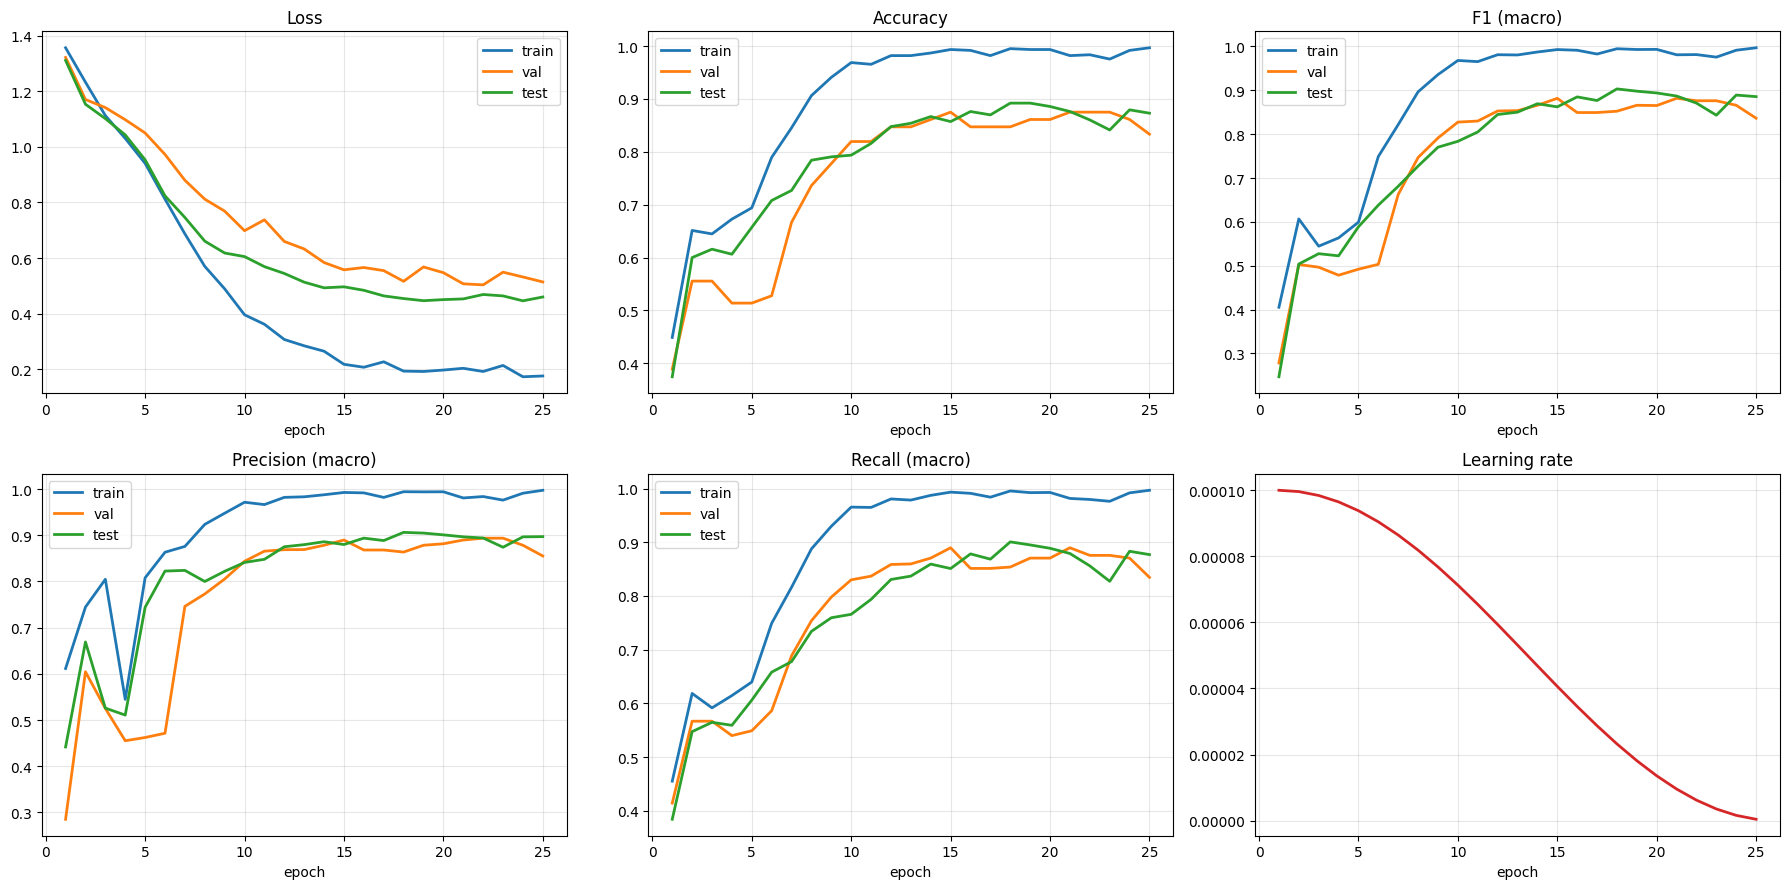

In [11]:
plot_loss_only(history)
plot_history(history, AVG)

## 8. Final evaluation (best-validation checkpoint)

In [12]:
import pandas as pd
res = {n: evaluate(model, l, criterion) for n, l in [("val", val_loader), ("test", test_loader)]}
rows = []
for n, (loss, y, p, prob) in res.items():
    m = metrics(y, p, AVG); m["loss"] = loss; m["auc"] = auc_score(y, prob); rows.append(pd.Series(m, name=n))
print(f"precision / recall / F1 = {AVG}-averaged")
print(pd.DataFrame(rows)[["loss", "acc", "precision", "recall", "f1", "auc"]].round(4))
_, ytest, ptest, probtest = res["test"]
print("\nTest classification report")
print(classification_report(ytest, ptest, target_names=CLASS_NAMES, digits=4, zero_division=0))

precision / recall / F1 = macro-averaged
        loss     acc  precision  recall      f1     auc
val   0.5034  0.8750     0.8938  0.8755  0.8763  0.9681
test  0.4687  0.8603     0.8941  0.8560  0.8708  0.9748

Test classification report
                         precision    recall  f1-score   support

         adenocarcinoma     0.7730    0.9083    0.8352       120
   large.cell.carcinoma     0.9048    0.7451    0.8172        51
                 normal     1.0000    0.9815    0.9907        54
squamous.cell.carcinoma     0.8987    0.7889    0.8402        90

               accuracy                         0.8603       315
              macro avg     0.8941    0.8560    0.8708       315
           weighted avg     0.8692    0.8603    0.8604       315



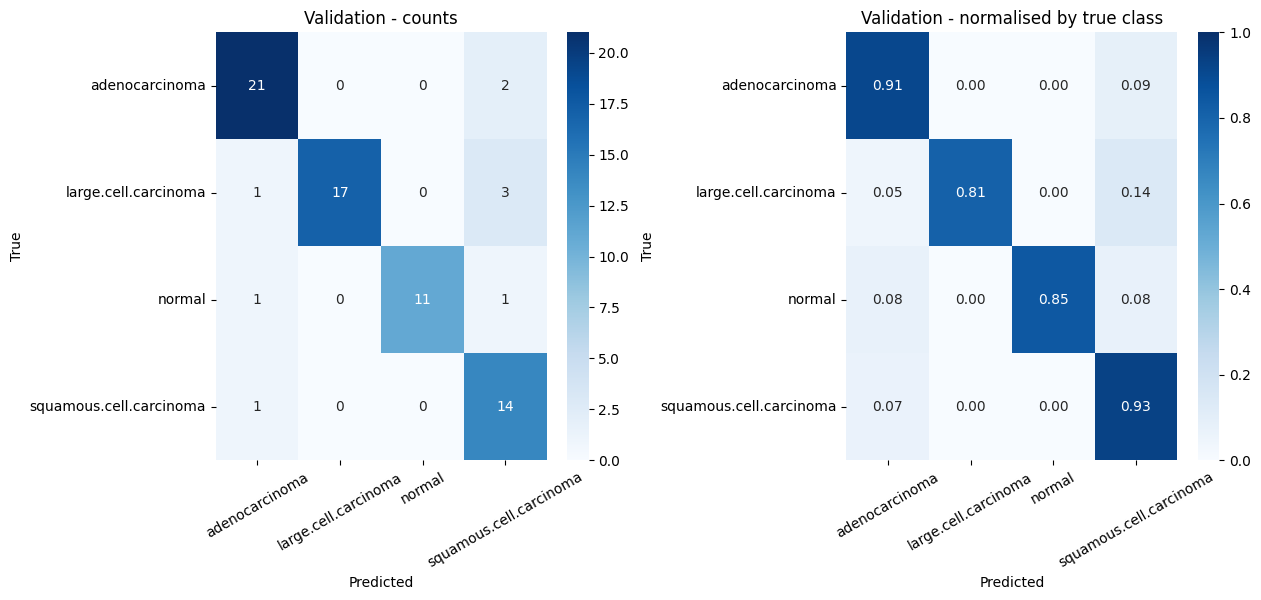

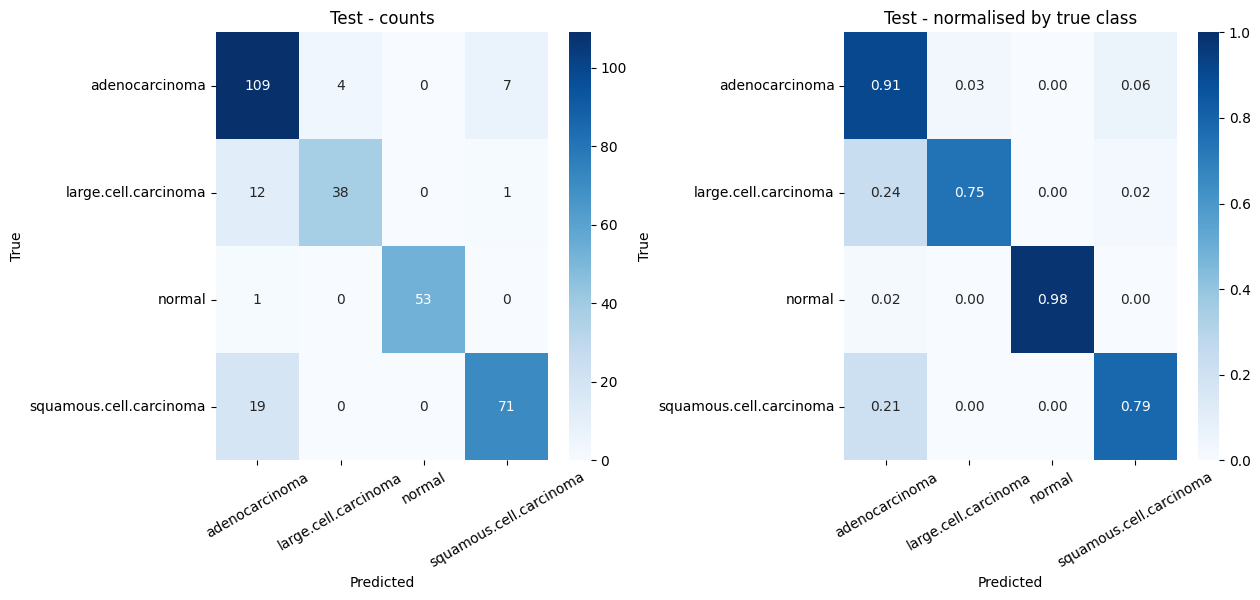

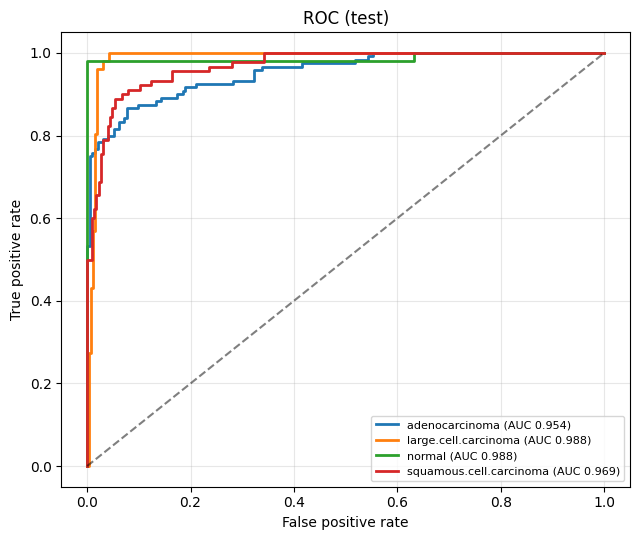

In [13]:
plot_confusion(res["val"][1], res["val"][2], CLASS_NAMES, "Validation", "confusion_val.png")
plot_confusion(ytest, ptest, CLASS_NAMES, "Test", "confusion_test.png")
plot_roc(ytest, probtest, CLASS_NAMES)

## Notes
- Plain training by default (no augmentation, no class weights); set `USE_AUGMENTATION` / `USE_CLASS_WEIGHTS` at the top to change it.
- Early stopping: patience 5 on validation loss; the best-validation-loss weights are restored. The variant is ShuffleNetV2 x1.0 (change `shufflenet_v2_x1_0` for x0.5 / x1.5 / x2.0).
- Batch size 16, 25 epochs. `PRETRAINED = True` needs the ImageNet / Hugging Face weights: turn Internet on in Kaggle (the notebook stops with a clear message if the download fails instead of silently training from scratch).
- Only about 600 training images, so results move noticeably between seeds; consider several seeds and report mean +/- std.
- Precision / recall / F1 in the curves are **macro** averages; the classification report also gives weighted averages.
- Images are decoded and resized once (224x224 grayscale), kept in memory as uint8 and fed straight to the model.